# Live SerialAnalysis signals
Run the install and setup cells, then use the receive check below to inspect raw serial bytes. Run the live graph cell separately. Each opens the port, so interrupt one before starting the other.


In [7]:
%pip install pyserial matplotlib

Note: you may need to restart the kernel to use updated packages.


In [1]:
from pathlib import Path
import sys
import time

# Allow launch from the repository root or the Live folder.
cwd = Path.cwd().resolve()
repo = cwd if (cwd / "SerialAnalysis" / "Live").is_dir() else cwd.parents[1]
if not (repo / "SerialAnalysis" / "Live").is_dir():
    raise RuntimeError("Start Jupyter from the repository root or SerialAnalysis/Live")
sys.path.insert(0, str(repo))

from IPython.display import display
from matplotlib import pyplot as plt
# Reload local code when rerunning setup after an edit.
import importlib
recorder_module = importlib.reload(importlib.import_module("SerialAnalysis.Live.recorder"))
plot_module = importlib.reload(importlib.import_module("SerialAnalysis.Live.live_plot"))
LiveRecorder = recorder_module.LiveRecorder
LivePlot = plot_module.LivePlot
print(f"Loaded recorder from {recorder_module.__file__}")

PORT = "COM8"
OUTPUT = repo / "sessions"
DURATION_MIN = 30
WINDOW_S = 5
REFRESH_S = 0.2


Loaded recorder from C:\Users\asher\projects\ece198\SerialAnalysis\Live\recorder.py


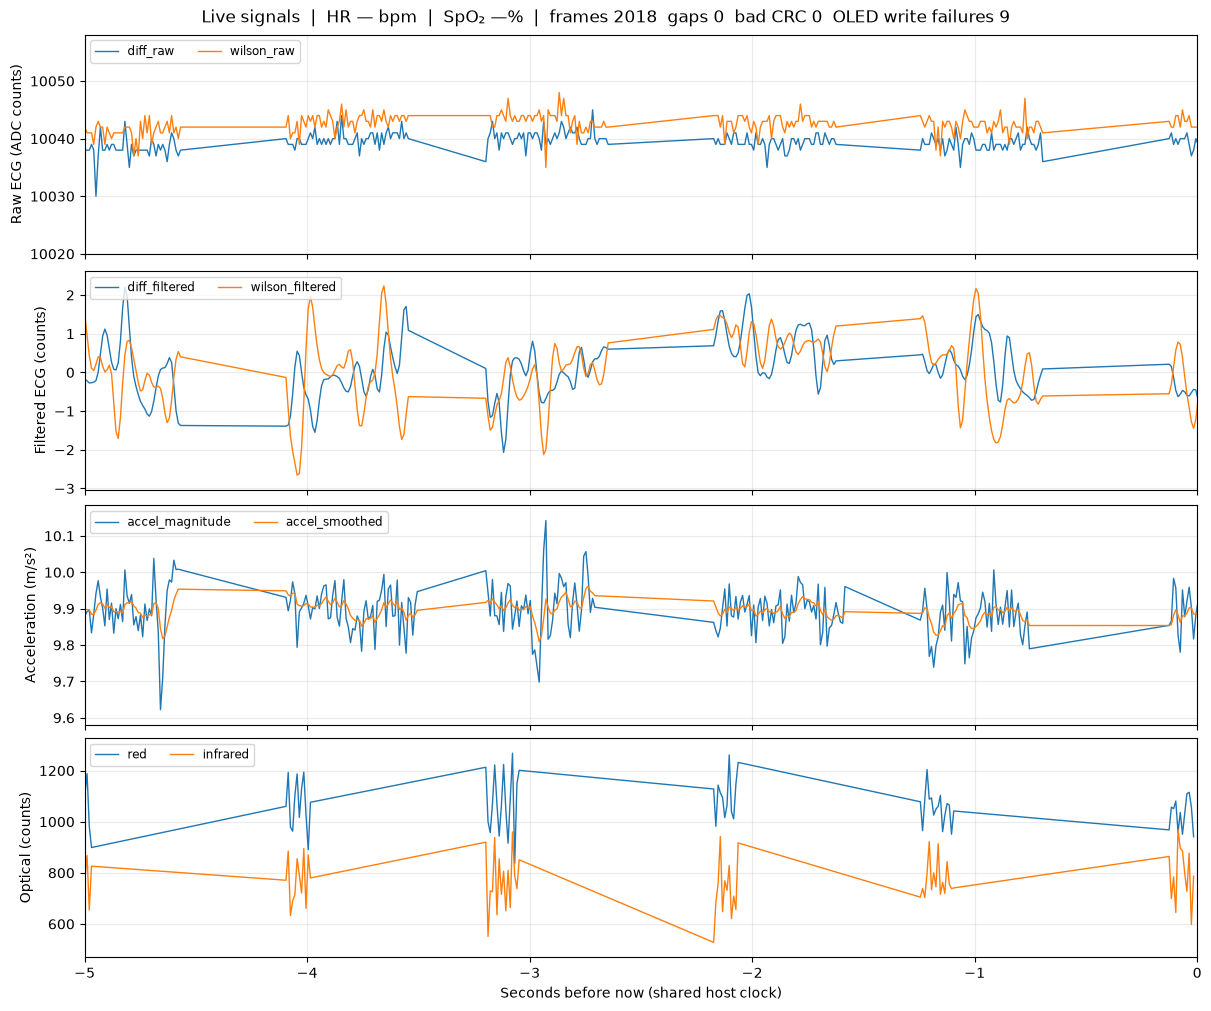

Recording to C:\Users\asher\projects\ece198\sessions\2026-11-19T22-46-00Z; interrupt this cell to stop.


In [ ]:
with LiveRecorder(PORT, OUTPUT, DURATION_MIN, window_s=WINDOW_S) as recorder:
    plot = LivePlot(WINDOW_S)
    handle = display(plot.figure, display_id=True)
    print(f"Recording to {recorder.session_dir}; interrupt this cell to stop.")
    last_refresh = 0.0
    try:
        while not recorder.done:
            recorder.poll()
            now = time.monotonic()
            if now - last_refresh >= REFRESH_S:
                plot.update(recorder)
                handle.update(plot.figure)
                last_refresh = now
    except KeyboardInterrupt:
        pass
    finally:
        plot.update(recorder)
        handle.update(plot.figure)
        plt.close(plot.figure)
        print(f"Finished: {recorder.session_dir}")


In [10]:
# Diagnostic: print incoming binary chunks and decoded frames for 10 seconds.
# Run this cell while the live graph cell is stopped.
from SerialAnalysis.Live.recorder import open_serial
from SerialAnalysis.Live.protocol import Decoder

MONITOR_SECONDS = 10
decoder = Decoder()
port = open_serial(PORT)
start = last_wait = time.monotonic()
received_bytes = received_frames = 0
print(f"Listening on {PORT} at {port.baudrate} baud, DTR={port.dtr}, for {MONITOR_SECONDS} seconds...", flush=True)
try:
    while time.monotonic() - start < MONITOR_SECONDS:
        chunk = port.read(1024)
        if chunk:
            received_bytes += len(chunk)
            print(f"RX {len(chunk)} bytes: {chunk.hex(' ')}", flush=True)
            frames = decoder.feed(chunk)
            received_frames += len(frames)
            for frame in frames:
                print(f"  frame type={frame.type} seq={frame.sequence} "
                      f"board_us={frame.timestamp_us} samples={frame.count}", flush=True)
        elif time.monotonic() - last_wait >= 1:
            print("Waiting for serial bytes...", flush=True)
            last_wait = time.monotonic()
except KeyboardInterrupt:
    print("Receive check interrupted.", flush=True)
finally:
    port.close()
    print(f"Closed {PORT}: {received_bytes} bytes, {received_frames} frames, "
          f"{decoder.bad} bad CRC/length frames.", flush=True)


Listening on COM8 at 115200 baud, DTR=True, for 10 seconds...
RX 198 bytes: a5 5a 01 86 03 68 86 1a 01 08 20 00 cd 0f 95 0c dc 0f 96 0c d1 0f 92 0c cf 0f 95 0c d1 0f 94 0c d0 0f 93 0c d1 0f 94 0c d0 0f 93 0c e5 4d a5 5a 03 87 03 18 16 42 02 04 30 00 18 16 42 02 d1 02 00 00 f4 02 00 00 46 b3 42 02 53 03 00 00 c0 02 00 00 7c 9e 43 02 d5 03 00 00 6f 03 00 00 e6 39 44 02 76 03 00 00 e8 02 00 00 40 4d a5 5a 02 88 03 c8 d9 42 02 05 1e 00 a4 e7 d0 ff c8 3b 30 e7 3c ff fc 3b ec e7 a8 00 0c 3b 44 e9 70 00 00 3d f4 e8 ac 00 e0 3c f5 75 a5 5a 01 89 03 a8 22 1b 01 08 20 00 cf 0f 94 0c cf 0f 98 0c dc 0f 93 0c d0 0f 95 0c d1 0f 95 0c cf 0f 95 0c d2 0f 93 0c ce 0f 93 0c a8 39
  frame type=1 seq=902 board_us=18515560 samples=8
  frame type=3 seq=903 board_us=37885464 samples=4
  frame type=2 seq=904 board_us=37935560 samples=5
  frame type=1 seq=905 board_us=18555560 samples=8
RX 90 bytes: a5 5a 02 8a 03 68 60 44 02 05 1e 00 14 e8 10 00 20 3d 40 e8 3c 00 70 3c c0 e8 7c 00 b8 3b 64 e8 28 00 20 3c 2c e8